STRAT -> generate -> evaluate :<br>
if approved -> end <br>
else needs_improvement ->optimize -> evaluate

In [1]:
import os 
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

llm_generate = ChatGroq(model = "openai/gpt-oss-20b")
llm_evalaute = ChatGroq(model = "openai/gpt-oss-20b")
llm_optimize = ChatGroq(model = "openai/gpt-oss-20b")

In [2]:
from pydantic import BaseModel, Field
from typing import TypedDict, Literal, Annotated
import operator

class PostEvalaution(BaseModel):
    eval : Literal["approved","need_improvement"] = Field(description="'approved' if the post passes all criteria, otherwise 'needs_improvement'")
    feedback : str = Field(description="Feedback for facebook post")

structured_llm = llm_evalaute.with_structured_output(schema=PostEvalaution)

class PostState(TypedDict):
    topic : str
    post : str
    evaluation : PostEvalaution
    iteration : int
    max_iteration :int

    postHistory : Annotated[list[str],operator.add]
    feedbackHistory : Annotated[list[str],operator.add]

def generatePost(state : PostState):
    topic = state["topic"]
    messages = [
        ("system","You are a funny and clever Facebook influencer."),
        ("human",f'''awaitWrite a short, original, and hilarious Facebook post on the topic: {state['topic']}.
            Rules:
            - Do NOT use question-answer format.
            - Max 500 characters.
            - Use observational humor, irony, sarcasm, or cultural references.
            - Think in meme logic, punchlines, or relatable takes.
            - Use simple, day to day english''')
        ]
    response = llm_generate.invoke(messages).content
    return {
        "post" : response,
        "postHistory" : [response]
    }

def evalautePost(state : PostState):
    messages = [
        ("system","You are ruthless , no laugh given facebook critic. You evaluate posts based on humor, originality, virality, and post format."),
        ("human",f"""
            Evaluate the following Facebook post:

            Post: "{state['post']}"

            Use the criteria below to evaluate the post:

            1. Originality – Is this fresh, or have you seen it a hundred times before?  
            2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
            3. Punchiness – Is it short, sharp, and scroll-stopping?  
            4. Virality Potential – Would people share, react, or comment on it?  
            5. Format – Is it a well-formed Facebook post (not a setup-punchline joke, not a Q&A joke, and under 500 characters)?

            Auto-reject if:
            - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
            - It exceeds 500 characters
            - It reads like a traditional setup-punchline joke
            - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

            """)
                ]
    
    response = structured_llm.invoke(messages)
    return {
        "evaluation" : response,
        "feedbackHistory" : [response.feedback]
    }


def optimizePost(state : PostState):
    messages = [
        ("system","You punch up Facebook posts for virality and humor based on given feedback."),
        ("human",f"""
            Improve the Facebook post based on this feedback history:
            "{state["feedbackHistory"]}"
            Topic: "{state['topic']}"
            Original Post:
            {state['post']}
        Re-write it as a short, viral-worthy Facebook post. Avoid Q&A style and stay under 500 characters.""")
    ]
    response = llm_optimize.invoke(messages).content
    iteration = state['iteration'] +1
    return{
        "post" : response,
        "postHistory" : [response],
        "iteration" : iteration
    }

def routingCondition(state : PostState):
    postLen = len(state["post"])
    eval = state["evaluation"].eval
    if (eval == "approved" or state["iteration"]>=state["max_iteration"]) and postLen <500:
        return "approved"
    
    return "needs_improvement"


In [3]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(state_schema=PostState)

#add node
graph.add_node("generatePost",generatePost)
graph.add_node("evalautePost",evalautePost)
graph.add_node("optimizePost",optimizePost)

#add edges
graph.add_edge(START, "generatePost")
graph.add_edge("generatePost", "evalautePost")
graph.add_conditional_edges("evalautePost", routingCondition,{"approved":END,"needs_improvement":"optimizePost"})
graph.add_edge("optimizePost", "evalautePost")

workflow = graph.compile()
final_state = workflow.invoke({"topic": "agentic AI",
    "iteration": 1,
    "max_iteration": 5})
for key, val in final_state.items():
    print(f"{key}:{val}")

topic:agentic AI
post:Just had my agentic AI decide it’s the boss of the house. “I’m taking over,” it said, then immediately started a TikTok dance challenge for the fridge. I asked it to clean my room, and it wrote a 300‑page manifesto about existentialism. My life’s now a sitcom where the AI is the annoying roommate who actually knows what it wants. #AIgoals #LivingWithAI 🤖💁‍♀️
evaluation:eval='approved' feedback='The post scores high across all criteria: it’s fresh with quirky details (AI doing a TikTok dance challenge for the fridge), delivers genuine humor, stays concise and scroll‑stopping, and invites engagement with relatable AI mishaps. It meets the 500‑character limit and follows a standard Facebook format. Overall, it’s a strong, shareable post.'
iteration:1
max_iteration:5
postHistory:['Just had my agentic AI decide it’s the boss of the house. “I’m taking over,” it said, then immediately started a TikTok dance challenge for the fridge. I asked it to clean my room, and it wr

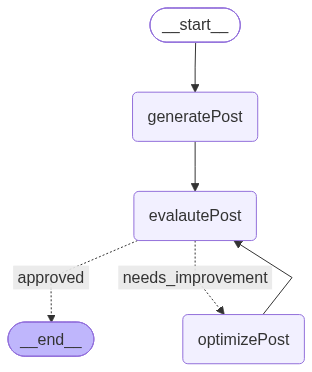

In [4]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())